<a href="https://colab.research.google.com/github/naweabaasa/NLP_END_OF_MODULE_PROJECT/blob/main/End_of_module_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Loading the dataset
from datasets import load_dataset

ds = load_dataset("stanfordnlp/imdb")
ds


print(ds)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


In [2]:
import pandas as pd

df = ds["train"].to_pandas()

print(df.head())


                                                text  label
0  I rented I AM CURIOUS-YELLOW from my video sto...      0
1  "I Am Curious: Yellow" is a risible and preten...      0
2  If only to avoid making this type of film in t...      0
3  This film was probably inspired by Godard's Ma...      0
4  Oh, brother...after hearing about this ridicul...      0


In [3]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check column names
print("Columns:", df.columns.tolist())

# Check data types and missing values
df.info()

Dataset shape: (25000, 2)
Columns: ['text', 'label']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    25000 non-null  object
 1   label   25000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 390.8+ KB


In [4]:
# Count positive and negative reviews
print(df["label"].value_counts())

# Check the distribution as percentages
print(df["label"].value_counts(normalize=True) * 100)

label
0    12500
1    12500
Name: count, dtype: int64
label
0    50.0
1    50.0
Name: proportion, dtype: float64


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Select the review text and sentiment labels
X_train = ds["train"]["text"]
y_train = ds["train"]["label"]

X_test = ds["test"]["text"]
y_test = ds["test"]["label"]

# Convert text into numerical features
tfidf = TfidfVectorizer(
    max_features=20000,
    stop_words="english"
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training features:", X_train_tfidf.shape)
print("Testing features:", X_test_tfidf.shape)

Training features: (25000, 20000)
Testing features: (25000, 20000)


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
import time

# Create the model
lr_model = LogisticRegression(max_iter=1000)

# Train the model
start_time = time.time()
lr_model.fit(X_train_tfidf, y_train)
lr_train_time = time.time() - start_time

print("Training time:", round(lr_train_time, 2), "seconds")

# Predict sentiments
lr_predictions = lr_model.predict(X_test_tfidf)

# Evaluate performance
print("Accuracy:", accuracy_score(y_test, lr_predictions))
print(classification_report(
    y_test,
    lr_predictions,
    target_names=["Negative", "Positive"]
))

Training time: 1.22 seconds
Accuracy: 0.87996
              precision    recall  f1-score   support

    Negative       0.88      0.88      0.88     12500
    Positive       0.88      0.88      0.88     12500

    accuracy                           0.88     25000
   macro avg       0.88      0.88      0.88     25000
weighted avg       0.88      0.88      0.88     25000



In [7]:
!pip install -q transformers accelerate

In [8]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

MODEL_NAME = "distilbert/distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

distilbert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [9]:
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=256
    )

tokenized_ds = ds.map(
    tokenize_function,
    batched=True
)

# Rename labels to the name expected by Trainer
tokenized_ds = tokenized_ds.rename_column(
    "label", "labels"
)

print(tokenized_ds)

DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 50000
    })
})


In [10]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision_score(labels, predictions),
        "recall": recall_score(labels, predictions),
        "f1": f1_score(labels, predictions)
    }

In [11]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

In [12]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./distilbert-imdb",
    num_train_epochs=1,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    eval_strategy="no",
    save_strategy="no",
    report_to="none"
)

In [13]:
from transformers import Trainer

small_train = tokenized_ds["train"].shuffle(
    seed=42
).select(range(2000))

small_test = tokenized_ds["test"].shuffle(
    seed=42
).select(range(500))


trainer = Trainer(
    model=distilbert_model,
    args=training_args,
    train_dataset=tokenized_ds["train"],
    eval_dataset=tokenized_ds["test"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

In [14]:
trainer.train()

Step,Training Loss
500,0.428495
1000,0.350643
1500,0.333776
2000,0.300419
2500,0.286417
3000,0.263167


TrainOutput(global_step=3125, training_loss=0.3255285534667969, metrics={'train_runtime': 590.9882, 'train_samples_per_second': 42.302, 'train_steps_per_second': 5.288, 'total_flos': 1654677184052448.0, 'train_loss': 0.3255285534667969, 'epoch': 1.0})

In [15]:
distilbert_results = trainer.evaluate()
print(distilbert_results)

Training Loss,Validation Loss,Step,Accuracy,Precision,Recall,F1
0.263167,0.269088,3125,0.910120,0.908258,0.912400,0.910324


{'eval_loss': 0.26908785104751587, 'eval_accuracy': 0.91012, 'eval_precision': 0.9082583419606594, 'eval_recall': 0.9124, 'eval_f1': 0.910324460230674}


In [17]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Get the same 500 test reviews
small_test_data = ds["test"].shuffle(
    seed=42
).select(range(500))

small_test_texts = small_test_data["text"]
small_test_labels = small_test_data["label"]

# Logistic Regression predictions (existing model)
X_small_test = tfidf.transform(small_test_texts)
lr_predictions = lr_model.predict(X_small_test)

# DistilBERT predictions (existing trained model)
distilbert_results = trainer.evaluate(small_test)

# Compare results
comparison_df = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(
            small_test_labels, lr_predictions
        ),
        "Precision": precision_score(
            small_test_labels, lr_predictions
        ),
        "Recall": recall_score(
            small_test_labels, lr_predictions
        ),
        "F1-score": f1_score(
            small_test_labels, lr_predictions
        )
    },
    {
        "Model": "DistilBERT",
        "Accuracy": distilbert_results["eval_accuracy"],
        "Precision": distilbert_results["eval_precision"],
        "Recall": distilbert_results["eval_recall"],
        "F1-score": distilbert_results["eval_f1"]
    }
])

comparison_df.round(4)

Training Loss,Validation Loss,Step,Accuracy,Precision,Recall,F1
0.263167,0.263941,3125,0.920000,0.922131,0.914634,0.918367


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.872,0.8760,0.8618,0.8689
1,DistilBERT,0.920,0.9221,0.9146,0.9184


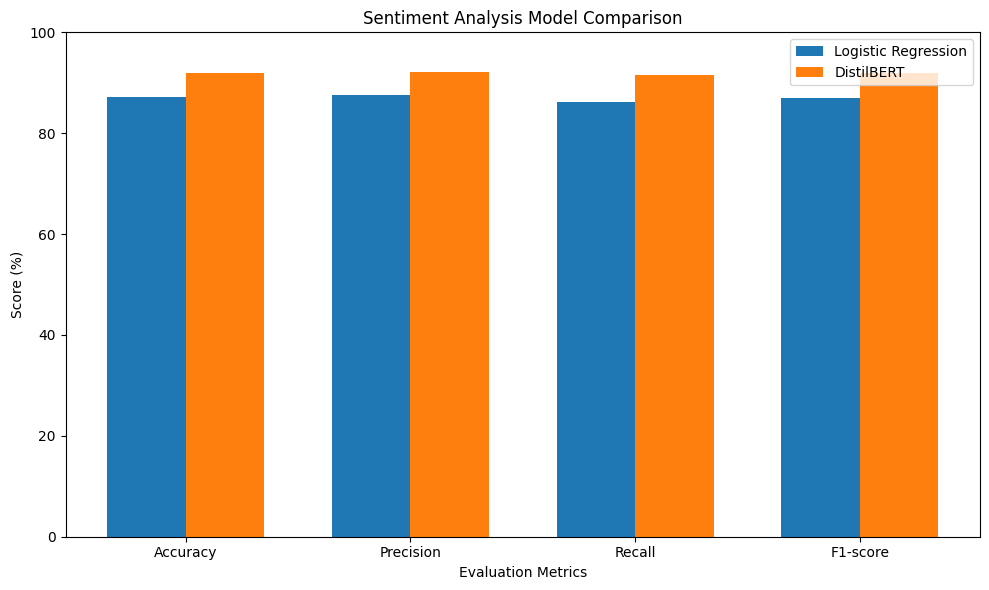

In [18]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

logistic = [87.20, 87.60, 86.18, 86.89]
distilbert = [92.00, 92.21, 91.46, 91.84]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(x - width/2, logistic, width, label="Logistic Regression")
plt.bar(x + width/2, distilbert, width, label="DistilBERT")

plt.ylabel("Score (%)")
plt.xlabel("Evaluation Metrics")
plt.title("Sentiment Analysis Model Comparison")
plt.xticks(x, metrics)
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()

plt.savefig("model_comparison.png", dpi=300)
plt.show()

In [19]:
# Let's test our trained DistilBERT model on custom sentences to verify its behavior
import torch
import torch.nn.functional as F

# Put model in evaluation mode
distilbert_model.eval()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
distilbert_model.to(device)

sample_texts = [
    "This movie was absolutely fantastic! The acting and storyline were top-notch.",
    "What a waste of time. The plot was boring and the acting was terrible."
]

for text in sample_texts:
    # Tokenize and move to device
    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=256).to(device)

    with torch.no_grad():
        outputs = distilbert_model(**inputs)
        # Apply softmax to get probabilities
        probs = F.softmax(outputs.logits, dim=-1)[0]
        prediction = torch.argmax(probs).item()

    sentiment = "Positive" if prediction == 1 else "Negative"
    confidence = probs[prediction].item() * 100

    print(f"Text: \"{text}\"")
    print(f"Predicted Sentiment: {sentiment} ({confidence:.2f}% confidence)\n")

Text: "This movie was absolutely fantastic! The acting and storyline were top-notch."
Predicted Sentiment: Positive (99.71% confidence)

Text: "What a waste of time. The plot was boring and the acting was terrible."
Predicted Sentiment: Negative (99.78% confidence)



### Step 1: Save the Model and Tokenizer
To ship the model, we first need to serialize and save both the fine-tuned model weights and the tokenizer configurations to a local directory.

In [ ]:
# Save model and tokenizer to a directory named 'shipped_distilbert_model'
saved_dir = "./shipped_distilbert_model"

trainer.save_model(saved_dir)
tokenizer.save_pretrained(saved_dir)

print(f"Model and Tokenizer successfully saved to: {saved_dir}")

### Step 2: How to load and use the saved model anywhere else
Once you have downloaded or copied the folder `./shipped_distilbert_model`, you can load it in any other Python environment with just two lines of code:

In [ ]:
# Example of loading the saved model for inference
from transformers import AutoTokenizer, AutoModelForSequenceClassification

loaded_tokenizer = AutoTokenizer.from_pretrained("./shipped_distilbert_model")
loaded_model = AutoModelForSequenceClassification.from_pretrained("./shipped_distilbert_model")

print("Model loaded successfully!")